# PCOS Risk Prediction — Final Corrected Modelling Notebook

## Final modelling design

This notebook keeps **REAL observations and synthetic augmentation strictly separated**.

```text
540 REAL observations
        ↓
Stratified 80:20 split BEFORE augmentation
        ↓
432 REAL development observations
108 REAL final holdout observations

Development-side training
        ↓
REAL training fold + synthetic records
        ↓
REAL-only validation fold

Final holdout
        ↓
108 REAL observations only
```

### Important methodological rules

1. The **108-record REAL holdout is not used for model selection**.
2. Candidate models are compared using **Repeated Stratified 5-Fold Cross-Validation × 10 repetitions** on the REAL development cohort.
3. Synthetic records are added **only to training folds**, never to validation folds or the final holdout. The generator is **refitted on each training fold**, so validation records never influence the synthetic data.
4. The final model is selected using a development-only selection criterion: **Balanced Accuracy**, with Recall and F1 as secondary criteria.
5. A development-only ablation compares **REAL-only training vs REAL + synthetic training**.
6. The final holdout is evaluated **once, after the model and training configuration have been fixed**.
7. The final predictive model is explained using **Linear SHAP**.
8. SHAP values are interpreted as **model attribution**, not medical causality.
9. The model is a **screening / decision-support prototype**, not a diagnostic system.

## Step 1 — Install packages and mount Google Drive

In [ ]:
!pip install -q interpret catboost shap joblib openpyxl

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## Step 2 — Imports and reproducibility settings

In [ ]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    RepeatedStratifiedKFold
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    matthews_corrcoef,
    brier_score_loss,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

from sklearn.calibration import CalibrationDisplay
from interpret.glassbox import ExplainableBoostingClassifier
from catboost import CatBoostClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("✅ Imports complete")

✅ Imports complete


## Step 3 — Load and prepare the REAL PCOS dataset

Only the 14 accessible predictors used by the final system and the binary target are retained.

The target is `PCOS (Y/N)`.

Laboratory, ultrasound, and clinician-dependent variables are not part of the user-facing model.

In [ ]:
REAL_FILE_PATH = "/content/drive/MyDrive/PCOS_data_without_infertility.xlsx"
REAL_SHEET_NAME = "Full_new"

TARGET = "PCOS (Y/N)"

FEATURE_COLUMNS = [
    "Age (yrs)",
    "BMI",
    "Cycle(R/I)",
    "Cycle length(days)",
    "Weight gain(Y/N)",
    "hair growth(Y/N)",
    "Skin darkening (Y/N)",
    "Hair loss(Y/N)",
    "Pimples(Y/N)",
    "Fast food (Y/N)",
    "Reg.Exercise(Y/N)",
    "Waist:Hip Ratio",
    "Waist(inch)",
    "Hip(inch)"
]

SELECTED_COLUMNS = FEATURE_COLUMNS + [TARGET]

real_raw = pd.read_excel(
    REAL_FILE_PATH,
    sheet_name=REAL_SHEET_NAME
)

real_raw.columns = real_raw.columns.str.strip()

missing_columns = [
    col for col in SELECTED_COLUMNS
    if col not in real_raw.columns
]

if missing_columns:
    raise ValueError(
        f"REAL dataset is missing required columns: {missing_columns}"
    )

real_df = (
    real_raw[SELECTED_COLUMNS]
    .copy()
    .dropna()
    .reset_index(drop=True)
)

real_df[TARGET] = real_df[TARGET].astype(int)

print("REAL dataset shape:", real_df.shape)
print("\nClass counts:")
print(real_df[TARGET].value_counts())

print("\nClass percentages:")
print(
    real_df[TARGET]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

assert len(real_df) == 540, (
    f"Expected 540 usable REAL records, found {len(real_df)}"
)

assert set(real_df[TARGET].unique()).issubset({0, 1})

print("\n✅ REAL dataset prepared")

REAL dataset shape: (540, 15)

Class counts:
PCOS (Y/N)
0    363
1    177
Name: count, dtype: int64

Class percentages:
PCOS (Y/N)
0    67.22
1    32.78
Name: proportion, dtype: float64

✅ REAL dataset prepared


## Step 4 — Create the untouched REAL final holdout

The REAL dataset is split **before** synthetic augmentation.

- **REAL development cohort:** 80%
- **REAL final holdout:** 20%
- `random_state = 42`
- stratification is applied using the binary target.

The final holdout must not be used to choose the model, threshold, hyperparameters, or augmentation strategy.

In [ ]:
X_real = real_df[FEATURE_COLUMNS].copy()
y_real = real_df[TARGET].copy()

X_dev, X_test, y_dev, y_test = train_test_split(
    X_real,
    y_real,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_real
)

print("Full REAL dataset:", X_real.shape)
print("REAL development set:", X_dev.shape)
print("Untouched REAL holdout:", X_test.shape)

print("\nDevelopment class distribution:")
print(y_dev.value_counts())
print(y_dev.value_counts(normalize=True).mul(100).round(2))

print("\nHoldout class distribution:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True).mul(100).round(2))

assert len(X_dev) == 432
assert len(X_test) == 108
assert set(X_dev.index).isdisjoint(set(X_test.index))

print("\n✅ REAL development/holdout split complete")

Full REAL dataset: (540, 14)
REAL development set: (432, 14)
Untouched REAL holdout: (108, 14)

Development class distribution:
PCOS (Y/N)
0    290
1    142
Name: count, dtype: int64
PCOS (Y/N)
0    67.13
1    32.87
Name: proportion, dtype: float64

Holdout class distribution:
PCOS (Y/N)
0    73
1    35
Name: count, dtype: int64
PCOS (Y/N)
0    67.59
1    32.41
Name: proportion, dtype: float64

✅ REAL development/holdout split complete


## Step 5 — Rule-based synthetic generator (refitted inside every training fold)

Synthetic observations are treated as **training augmentation only**.

The generator is written as a function so that it can be **refitted on each cross-validation training fold**. This prevents validation-fold records from influencing the synthetic data, which would otherwise make development scores slightly optimistic.

- **Inside CV:** generator fitted on the REAL training fold only → synthetic records added to that fold's training side.
- **Final model:** generator fitted on the 432 REAL development records.
- **Holdout:** the 108 REAL holdout records are never passed to the generator.

This is the **same generator** as `PCOS_Synthetic_Generator_Development_Only` (same buckets, label rule and random-draw order). With seed 42 on the 432 development records it reproduces the earlier 600-record file, so the final model's training data is unchanged.


In [ ]:
# ============================================================
# ORIGINAL RULE-BASED SYNTHETIC GENERATOR — as a per-fold function
# ============================================================
# This is the same generator as "PCOS_Synthetic_Generator_Development_Only"
# (same buckets, label rule, BMI/lean design, fixed height assumption and
# the same order of random draws). The only change: it is a FUNCTION that
# is fitted on whatever REAL records it receives.
#   - Inside CV  -> fitted on the REAL training fold only
#   - Final model -> fitted on the 432 REAL development records
#   - Holdout     -> never passed to it

BINARY_LIFESTYLE_COLS = ['Weight gain(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)']
GEN_CONTINUOUS_COLS = ['Age (yrs)', 'Cycle length(days)', 'Hip(inch)', 'Waist(inch)']
HEIGHT_MEAN, HEIGHT_STD = 160.0, 7.0      # fixed generation assumption (not fitted)

BUCKET_COUNTS = [
    ('path1_classic',    False, 90),
    ('path1_lean',       True,  30),
    ('path2_classic',    False, 60),
    ('path2_lean',       True,  30),
    ('neg_regular',      False, 280),
    ('neg_irregular',    False, 80),
    ('neg_lean_control', True,  30),
]


def truncated_normal(mean, std, low, high):
    """Sample from N(mean, std) clipped to [low, high]."""
    if std == 0 or np.isnan(std):
        return float(mean)
    return float(np.clip(np.random.normal(mean, std), low, high))


def pcos_rule(cycle, hair_growth, hair_loss, pimples, skin):
    """Study-specific symptom heuristic (not a clinical diagnosis).
    A: irregular cycle (cycle == 4)
    Path 1: hair_loss AND hair_growth
    Path 2: (hair_loss OR hair_growth) AND pimples AND skin darkening"""
    criterion_A = (cycle == 4)
    path_1 = (hair_growth == 1 and hair_loss == 1)
    path_2 = ((hair_growth == 1 or hair_loss == 1) and pimples == 1 and skin == 1)
    return int(criterion_A and (path_1 or path_2))


def assign_symptoms(bucket):
    """Symptom flags guaranteed consistent with the labelling rule."""
    if bucket in ('path1_classic', 'path1_lean'):
        cycle, hair_growth, hair_loss = 4, 1, 1
        pimples = np.random.choice([0, 1], p=[0.4, 0.6])
        skin    = np.random.choice([0, 1], p=[0.4, 0.6])
    elif bucket in ('path2_classic', 'path2_lean'):
        cycle, pimples, skin = 4, 1, 1
        pattern     = np.random.choice(['loss_only', 'growth_only', 'both'], p=[0.35, 0.35, 0.30])
        hair_loss   = 1 if pattern in ('loss_only', 'both') else 0
        hair_growth = 1 if pattern in ('growth_only', 'both') else 0
    elif bucket == 'neg_regular':
        cycle       = 2
        hair_growth = np.random.choice([0, 1], p=[0.85, 0.15])
        hair_loss   = np.random.choice([0, 1], p=[0.85, 0.15])
        pimples     = np.random.choice([0, 1], p=[0.70, 0.30])
        skin        = np.random.choice([0, 1], p=[0.85, 0.15])
    elif bucket == 'neg_irregular':
        cycle = 4
        while True:
            hair_growth = np.random.choice([0, 1], p=[0.6, 0.4])
            hair_loss   = np.random.choice([0, 1], p=[0.6, 0.4])
            pimples     = np.random.choice([0, 1], p=[0.6, 0.4])
            skin        = np.random.choice([0, 1], p=[0.7, 0.3])
            if pcos_rule(cycle, hair_growth, hair_loss, pimples, skin) == 0:
                break
    elif bucket == 'neg_lean_control':
        cycle = np.random.choice([2, 4], p=[0.8, 0.2])
        while True:
            hair_growth = np.random.choice([0, 1], p=[0.85, 0.15])
            hair_loss   = np.random.choice([0, 1], p=[0.85, 0.15])
            pimples     = np.random.choice([0, 1], p=[0.75, 0.25])
            skin        = np.random.choice([0, 1], p=[0.85, 0.15])
            if pcos_rule(cycle, hair_growth, hair_loss, pimples, skin) == 0:
                break
    return cycle, hair_growth, hair_loss, pimples, skin


def fit_generator_stats(X_src, y_src):
    """Class-specific statistics from the REAL records passed in ONLY."""
    src = X_src.copy()
    src[TARGET] = np.asarray(y_src)

    def stats(col, label):
        v = src.loc[src[TARGET] == label, col]
        return (v.mean(), v.std(), v.min(), v.max())

    cont_stats = {c: {lab: stats(c, lab) for lab in [0, 1]} for c in GEN_CONTINUOUS_COLS}
    bmi_stats = {lab: stats('BMI', lab) for lab in [0, 1]}
    lifestyle_p = {
        c: {lab: src.loc[src[TARGET] == lab, c].mean() for lab in [0, 1]}
        for c in BINARY_LIFESTYLE_COLS
    }
    return cont_stats, bmi_stats, lifestyle_p


def generate_synthetic(X_src, y_src, seed=RANDOM_STATE):
    """Fit the generator on X_src/y_src and return 600 synthetic records
    (14 modelling features + label). Same logic as the original generator."""
    cont_stats, bmi_stats, lifestyle_p = fit_generator_stats(X_src, y_src)

    np.random.seed(seed)
    bucket_plan = []
    for name, is_lean, count in BUCKET_COUNTS:
        bucket_plan += [(name, is_lean)] * count
    assert len(bucket_plan) == 600
    np.random.shuffle(bucket_plan)

    rows = []
    for bucket, is_lean in bucket_plan:
        cycle, hair_growth, hair_loss, pimples, skin = assign_symptoms(bucket)
        label = pcos_rule(cycle, hair_growth, hair_loss, pimples, skin)
        if is_lean:
            bmi = truncated_normal(16.6, 1.4, 12.0, 18.4)
        else:
            m, s, lo, hi = bmi_stats[label]
            bmi = truncated_normal(m, s, max(lo, 18.5), hi)
        height = truncated_normal(HEIGHT_MEAN, HEIGHT_STD, 145, 180)   # drawn to keep the original random sequence
        row = {
            'Age (yrs)': round(truncated_normal(*cont_stats['Age (yrs)'][label])),
            'BMI': round(bmi, 6),
            'Cycle(R/I)': cycle,
            'Cycle length(days)': round(truncated_normal(*cont_stats['Cycle length(days)'][label])),
            'Hip(inch)': round(truncated_normal(*cont_stats['Hip(inch)'][label])),
            'Waist(inch)': round(truncated_normal(*cont_stats['Waist(inch)'][label])),
            'Weight gain(Y/N)': int(np.random.choice([0, 1], p=[1 - lifestyle_p['Weight gain(Y/N)'][label], lifestyle_p['Weight gain(Y/N)'][label]])),
            'hair growth(Y/N)': hair_growth,
            'Skin darkening (Y/N)': skin,
            'Hair loss(Y/N)': hair_loss,
            'Pimples(Y/N)': pimples,
            'Fast food (Y/N)': int(np.random.choice([0, 1], p=[1 - lifestyle_p['Fast food (Y/N)'][label], lifestyle_p['Fast food (Y/N)'][label]])),
            'Reg.Exercise(Y/N)': int(np.random.choice([0, 1], p=[1 - lifestyle_p['Reg.Exercise(Y/N)'][label], lifestyle_p['Reg.Exercise(Y/N)'][label]])),
            TARGET: label,
        }
        row['Waist:Hip Ratio'] = round(row['Waist(inch)'] / row['Hip(inch)'], 4) if row['Hip(inch)'] != 0 else 0.0
        rows.append(row)

    syn = pd.DataFrame(rows)
    return syn[FEATURE_COLUMNS].copy(), syn[TARGET].astype(int).copy()


# ------------------------------------------------------------
# Synthetic set for the FINAL model only (fitted on all 432 dev records).
# Cross-validation does NOT use this set; it regenerates per fold.
# ------------------------------------------------------------
X_synthetic, y_synthetic = generate_synthetic(X_dev, y_dev, seed=RANDOM_STATE)

rule_check = [
    pcos_rule(r['Cycle(R/I)'], r['hair growth(Y/N)'], r['Hair loss(Y/N)'],
              r['Pimples(Y/N)'], r['Skin darkening (Y/N)'])
    for _, r in X_synthetic.iterrows()
]
assert len(X_synthetic) == 600
assert list(X_synthetic.columns) == FEATURE_COLUMNS
assert (np.array(rule_check) == y_synthetic.values).all()

print("Final-model synthetic feature matrix:", X_synthetic.shape)
print("Synthetic class counts:", y_synthetic.value_counts().to_dict())
print("Rule mismatches: 0")

# ------------------------------------------------------------
# Optional: confirm this reproduces your earlier 600-record file
# ------------------------------------------------------------
OLD_SYNTHETIC_FILE = "/content/drive/MyDrive/PCOS_synthetic_600_rule_based.xlsx"
if os.path.exists(OLD_SYNTHETIC_FILE):
    old = pd.read_excel(OLD_SYNTHETIC_FILE)
    old.columns = old.columns.str.strip()
    same = np.allclose(
        old[FEATURE_COLUMNS].astype(float).values,
        X_synthetic.astype(float).values
    ) and (old[TARGET].astype(int).values == y_synthetic.values).all()
    print("Matches the earlier generator file:", bool(same))

print("\n✅ Generator ready; final-model synthetic set built from development data only")


Final-model synthetic feature matrix: (600, 14)
Synthetic class counts: {0: 390, 1: 210}
Rule mismatches: 0
Matches the earlier generator file: True

✅ Generator ready; final-model synthetic set built from development data only


## Step 6 — Integrity audit: exact synthetic/holdout profile overlap

This is an **evaluation-integrity check**, not a model-selection step.

The code checks whether an exact 14-feature synthetic profile duplicates an observation in the untouched REAL holdout.

If exact overlap is detected, do **not** silently remove records after seeing holdout performance. Regenerate the synthetic dataset independently and restart the experiment.

In [ ]:
def canonical_profile_keys(df, decimals=6):
    temp = df[FEATURE_COLUMNS].copy()

    for col in FEATURE_COLUMNS:
        temp[col] = pd.to_numeric(
            temp[col],
            errors="coerce"
        ).round(decimals)

    return temp.astype(str).agg("||".join, axis=1)


holdout_profile_keys = set(
    canonical_profile_keys(X_test)
)

synthetic_profile_keys = set(
    canonical_profile_keys(X_synthetic)
)

exact_profile_overlap = (
    holdout_profile_keys
    & synthetic_profile_keys
)

print(
    "Exact synthetic/REAL-holdout feature-profile overlaps:",
    len(exact_profile_overlap)
)

if len(exact_profile_overlap) > 0:
    raise ValueError(
        "Exact synthetic/holdout profile overlap detected. "
        "Regenerate the synthetic dataset independently before "
        "running the final experiment."
    )

print("✅ No exact 14-feature profile overlap detected")

Exact synthetic/REAL-holdout feature-profile overlaps: 0
✅ No exact 14-feature profile overlap detected


## Step 7 — Logistic Regression preprocessing

Only continuous variables are standardized. Binary-like/coded variables are passed through unchanged.

The preprocessing is stored inside a scikit-learn `Pipeline`, so the **same transformation is applied during training and inference**.

In [ ]:
CONTINUOUS_FEATURES = [
    "Age (yrs)",
    "BMI",
    "Cycle length(days)",
    "Waist:Hip Ratio",
    "Waist(inch)",
    "Hip(inch)"
]

OTHER_FEATURES = [
    col for col in FEATURE_COLUMNS
    if col not in CONTINUOUS_FEATURES
]

lr_preprocessor = ColumnTransformer(
    transformers=[
        (
            "scale",
            StandardScaler(),
            CONTINUOUS_FEATURES
        )
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

print("Continuous features:")
print(CONTINUOUS_FEATURES)

print("\nPassed-through coded/binary-like features:")
print(OTHER_FEATURES)

print("\n✅ Logistic preprocessing defined")

Continuous features:
['Age (yrs)', 'BMI', 'Cycle length(days)', 'Waist:Hip Ratio', 'Waist(inch)', 'Hip(inch)']

Passed-through coded/binary-like features:
['Cycle(R/I)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)']

✅ Logistic preprocessing defined


## Step 8 — Candidate models

Four candidate configurations are compared:

1. Standard Logistic Regression
2. Balanced Logistic Regression
3. Explainable Boosting Machine (EBM)
4. CatBoost

### Model-selection rule used in the final analysis

Because this study is a **screening / decision-support prototype**, the primary development metric is:

**1. Balanced Accuracy**

If models are effectively tied, use:

**2. Recall/Sensitivity**  
**3. F1-score**  
**4. MCC**

The final holdout is **not** part of this selection rule.

In [ ]:
logistic_model = Pipeline([
    (
        "preprocess",
        clone(lr_preprocessor)
    ),
    (
        "model",
        LogisticRegression(
            solver="liblinear",
            max_iter=2000,
            random_state=RANDOM_STATE
        )
    )
])

logistic_balanced_model = Pipeline([
    (
        "preprocess",
        clone(lr_preprocessor)
    ),
    (
        "model",
        LogisticRegression(
            solver="liblinear",
            class_weight="balanced",
            max_iter=2000,
            random_state=RANDOM_STATE
        )
    )
])

ebm_model = ExplainableBoostingClassifier(
    interactions=3,
    random_state=RANDOM_STATE,
    n_jobs=-2
)

catboost_model = CatBoostClassifier(
    iterations=300,
    depth=4,
    learning_rate=0.03,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=RANDOM_STATE,
    verbose=0
)

MODELS = {
    "Logistic Regression": logistic_model,
    "Balanced Logistic Regression": logistic_balanced_model,
    "EBM": ebm_model,
    "CatBoost": catboost_model
}

print("Candidate models:")
for name in MODELS:
    print("-", name)

Candidate models:
- Logistic Regression
- Balanced Logistic Regression
- EBM
- CatBoost


## Step 9 — Evaluation helpers

In [ ]:
def binary_metrics(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Specificity": specificity,
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
        "MCC": matthews_corrcoef(y_true, y_pred)
    }


def run_augmented_repeated_cv(
    models,
    X_real_dev,
    y_real_dev,
    X_synthetic,
    y_synthetic,
    splitter,
    random_state=42
):
    # Split only REAL development observations.
    # Synthetic records are regenerated from each training fold
    # and added to the training side only.

    result_rows = []
    fold_details = {}

    for model_name, model in models.items():

        print("\n" + "=" * 72)
        print("Evaluating:", model_name)
        print("=" * 72)

        fold_rows = []

        for fold_no, (train_idx, val_idx) in enumerate(
            splitter.split(
                X_real_dev,
                y_real_dev
            ),
            start=1
        ):
            X_train_real = (
                X_real_dev
                .iloc[train_idx]
                .reset_index(drop=True)
            )

            y_train_real = (
                y_real_dev
                .iloc[train_idx]
                .reset_index(drop=True)
            )

            X_val_real = (
                X_real_dev
                .iloc[val_idx]
                .copy()
            )

            y_val_real = (
                y_real_dev
                .iloc[val_idx]
                .copy()
            )

            # Refit the generator on THIS REAL training fold only
            X_syn_fold, y_syn_fold = generate_synthetic(
                X_train_real,
                y_train_real,
                seed=random_state + fold_no
            )

            X_train_aug = pd.concat(
                [
                    X_train_real,
                    X_syn_fold
                ],
                ignore_index=True
            )

            y_train_aug = pd.concat(
                [
                    y_train_real,
                    y_syn_fold
                ],
                ignore_index=True
            )

            order = np.random.RandomState(
                random_state + fold_no
            ).permutation(
                len(X_train_aug)
            )

            X_train_aug = (
                X_train_aug
                .iloc[order]
                .reset_index(drop=True)
            )

            y_train_aug = (
                y_train_aug
                .iloc[order]
                .reset_index(drop=True)
            )

            fitted = clone(model)

            fitted.fit(
                X_train_aug,
                y_train_aug
            )

            y_prob = fitted.predict_proba(
                X_val_real
            )[:, 1]

            y_pred = fitted.predict(
                X_val_real
            )

            row = binary_metrics(
                y_val_real,
                y_pred,
                y_prob
            )

            row["Fold"] = fold_no
            fold_rows.append(row)

        fold_df = pd.DataFrame(
            fold_rows
        )

        fold_details[model_name] = fold_df

        summary = {"Model": model_name}

        for metric in [
            "Accuracy",
            "Balanced Accuracy",
            "Precision",
            "Recall",
            "Specificity",
            "F1",
            "ROC-AUC",
            "PR-AUC",
            "MCC"
        ]:
            summary[f"{metric} Mean"] = fold_df[metric].mean()
            summary[f"{metric} SD"] = fold_df[metric].std(ddof=0)

        result_rows.append(summary)

    return pd.DataFrame(result_rows), fold_details

## Step 10 — Final development comparison: 5-fold × 10 repeats

This is the **primary candidate-model comparison**.

Each model receives 50 REAL-only validation evaluations. In every fold, the generator is refitted on the REAL training fold and its synthetic records are added only to the training side.

In [ ]:
FINAL_CV = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=RANDOM_STATE
)

final_cv_results_df, final_cv_fold_details = (
    run_augmented_repeated_cv(
        models=MODELS,
        X_real_dev=X_dev,
        y_real_dev=y_dev,
        X_synthetic=X_synthetic,
        y_synthetic=y_synthetic,
        splitter=FINAL_CV,
        random_state=RANDOM_STATE
    )
)

print("\n✅ 5×10 development CV complete")
print("All validation observations were REAL.")

display(
    final_cv_results_df.round(4)
)


Evaluating: Logistic Regression

Evaluating: Balanced Logistic Regression

Evaluating: EBM

Evaluating: CatBoost

✅ 5×10 development CV complete
All validation observations were REAL.


,Model,Accuracy Mean,Accuracy SD,Balanced Accuracy Mean,Balanced Accuracy SD,Precision Mean,Precision SD,Recall Mean,Recall SD,Specificity Mean,Specificity SD,F1 Mean,F1 SD,ROC-AUC Mean,ROC-AUC SD,PR-AUC Mean,PR-AUC SD,MCC Mean,MCC SD
0,Logistic Regression,0.8555,0.0310,0.8116,0.0448,0.8481,0.0461,0.6835,0.0895,0.9397,0.0202,0.7538,0.0645,0.8802,0.0322,0.8290,0.0510,0.6636,0.0757
1,Balanced Logistic Regression,0.8479,0.0344,0.8241,0.0412,0.7808,0.0672,0.7547,0.0770,0.8934,0.0396,0.7645,0.0559,0.8809,0.0321,0.8301,0.0508,0.6554,0.0787
2,EBM,0.8491,0.0341,0.8018,0.0458,0.8476,0.0645,0.6639,0.0907,0.9397,0.0322,0.7405,0.0657,0.8838,0.0319,0.8352,0.0506,0.6492,0.0817
3,CatBoost,0.8514,0.0323,0.8004,0.0453,0.8655,0.0584,0.6515,0.0896,0.9493,0.0237,0.7396,0.0664,0.8858,0.0304,0.8470,0.0457,0.6543,0.0785


## Step 11 — Select the candidate model using development CV only

The model is ranked using the development-only criterion:

1. highest mean Balanced Accuracy;
2. then highest mean Recall;
3. then highest mean F1;
4. then highest mean MCC.

With the previously observed results from this dataset, this procedure selects **Balanced Logistic Regression**. The code performs the selection automatically so the notebook remains reproducible.

In [ ]:
MODEL_SELECTION_TABLE = (
    final_cv_results_df
    .sort_values(
        by=[
            "Balanced Accuracy Mean",
            "Recall Mean",
            "F1 Mean",
            "MCC Mean"
        ],
        ascending=[
            False,
            False,
            False,
            False
        ]
    )
    .reset_index(drop=True)
)

display(
    MODEL_SELECTION_TABLE[
        [
            "Model",
            "Balanced Accuracy Mean",
            "Recall Mean",
            "F1 Mean",
            "MCC Mean",
            "ROC-AUC Mean",
            "PR-AUC Mean",
            "Specificity Mean",
            "Precision Mean"
        ]
    ].round(4)
)

SELECTED_MODEL_NAME = (
    MODEL_SELECTION_TABLE.iloc[0]["Model"]
)

SELECTED_MODEL_TEMPLATE = MODELS[
    SELECTED_MODEL_NAME
]

print(
    "\nSelected model from development CV:",
    SELECTED_MODEL_NAME
)

,Model,Balanced Accuracy Mean,Recall Mean,F1 Mean,MCC Mean,ROC-AUC Mean,PR-AUC Mean,Specificity Mean,Precision Mean
0,Balanced Logistic Regression,0.8241,0.7547,0.7645,0.6554,0.8809,0.8301,0.8934,0.7808
1,Logistic Regression,0.8116,0.6835,0.7538,0.6636,0.8802,0.8290,0.9397,0.8481
2,EBM,0.8018,0.6639,0.7405,0.6492,0.8838,0.8352,0.9397,0.8476
3,CatBoost,0.8004,0.6515,0.7396,0.6543,0.8858,0.8470,0.9493,0.8655



Selected model from development CV: Balanced Logistic Regression


## Step 12 — Synthetic augmentation ablation for the selected model

The selected model is evaluated under two **development-only** training configurations:

- `REAL_ONLY`: train on the REAL training fold only.
- `REAL_PLUS_SYNTHETIC`: train on the same REAL training fold plus synthetic observations regenerated from that training fold only.

Validation remains REAL-only in both cases.

This tests whether synthetic augmentation actually helps before the final holdout is touched.

In [ ]:
def run_augmentation_ablation(
    model,
    X_real_dev,
    y_real_dev,
    X_synthetic,
    y_synthetic,
    splitter,
    random_state=42
):
    configuration_rows = []
    all_fold_details = {}

    for configuration in [
        "REAL_ONLY",
        "REAL_PLUS_SYNTHETIC"
    ]:

        fold_rows = []

        for fold_no, (train_idx, val_idx) in enumerate(
            splitter.split(
                X_real_dev,
                y_real_dev
            ),
            start=1
        ):
            X_train_real = (
                X_real_dev
                .iloc[train_idx]
                .reset_index(drop=True)
            )

            y_train_real = (
                y_real_dev
                .iloc[train_idx]
                .reset_index(drop=True)
            )

            X_val_real = (
                X_real_dev
                .iloc[val_idx]
                .copy()
            )

            y_val_real = (
                y_real_dev
                .iloc[val_idx]
                .copy()
            )

            if configuration == "REAL_ONLY":
                X_train = X_train_real.copy()
                y_train = y_train_real.copy()

            else:
                # Refit the generator on THIS REAL training fold only
                X_syn_fold, y_syn_fold = generate_synthetic(
                    X_train_real,
                    y_train_real,
                    seed=random_state + fold_no
                )

                X_train = pd.concat(
                    [
                        X_train_real,
                        X_syn_fold
                    ],
                    ignore_index=True
                )

                y_train = pd.concat(
                    [
                        y_train_real,
                        y_syn_fold
                    ],
                    ignore_index=True
                )

                order = np.random.RandomState(
                    random_state + fold_no
                ).permutation(
                    len(X_train)
                )

                X_train = (
                    X_train
                    .iloc[order]
                    .reset_index(drop=True)
                )

                y_train = (
                    y_train
                    .iloc[order]
                    .reset_index(drop=True)
                )

            fitted = clone(model)

            fitted.fit(
                X_train,
                y_train
            )

            y_prob = fitted.predict_proba(
                X_val_real
            )[:, 1]

            y_pred = fitted.predict(
                X_val_real
            )

            row = binary_metrics(
                y_val_real,
                y_pred,
                y_prob
            )

            row["Fold"] = fold_no
            fold_rows.append(row)

        fold_df = pd.DataFrame(fold_rows)
        all_fold_details[configuration] = fold_df

        summary = {
            "Training Configuration":
                configuration
        }

        for metric in [
            "Accuracy",
            "Balanced Accuracy",
            "Precision",
            "Recall",
            "Specificity",
            "F1",
            "ROC-AUC",
            "PR-AUC",
            "MCC"
        ]:
            summary[f"{metric} Mean"] = fold_df[metric].mean()
            summary[f"{metric} SD"] = fold_df[metric].std(ddof=0)

        configuration_rows.append(summary)

    return (
        pd.DataFrame(configuration_rows),
        all_fold_details
    )


ABLATION_CV = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=RANDOM_STATE
)

augmentation_ablation_df, augmentation_ablation_folds = (
    run_augmentation_ablation(
        model=SELECTED_MODEL_TEMPLATE,
        X_real_dev=X_dev,
        y_real_dev=y_dev,
        X_synthetic=X_synthetic,
        y_synthetic=y_synthetic,
        splitter=ABLATION_CV,
        random_state=RANDOM_STATE
    )
)

display(
    augmentation_ablation_df[
        [
            "Training Configuration",
            "Balanced Accuracy Mean",
            "Recall Mean",
            "F1 Mean",
            "MCC Mean",
            "ROC-AUC Mean",
            "PR-AUC Mean",
            "Specificity Mean",
            "Precision Mean"
        ]
    ].round(4)
)

,Training Configuration,Balanced Accuracy Mean,Recall Mean,F1 Mean,MCC Mean,ROC-AUC Mean,PR-AUC Mean,Specificity Mean,Precision Mean
0,REAL_ONLY,0.8164,0.8025,0.7465,0.6162,0.8826,0.8312,0.8303,0.7029
1,REAL_PLUS_SYNTHETIC,0.8241,0.7547,0.7645,0.6554,0.8809,0.8301,0.8934,0.7808


## Step 13 — Fix the final training configuration before holdout evaluation

The augmentation configuration is selected using the **same development criterion**:

1. Balanced Accuracy;
2. Recall;
3. F1;
4. MCC.

No holdout result is used here.

The operating threshold is retained at **0.50**. It is a research threshold and is not claimed to be clinically optimal.

In [ ]:
ABLATION_SELECTION_TABLE = (
    augmentation_ablation_df
    .sort_values(
        by=[
            "Balanced Accuracy Mean",
            "Recall Mean",
            "F1 Mean",
            "MCC Mean"
        ],
        ascending=[
            False,
            False,
            False,
            False
        ]
    )
    .reset_index(drop=True)
)

SELECTED_TRAINING_CONFIGURATION = (
    ABLATION_SELECTION_TABLE
    .iloc[0]["Training Configuration"]
)

SELECTED_THRESHOLD = 0.50

print("Selected model:", SELECTED_MODEL_NAME)
print(
    "Selected training configuration:",
    SELECTED_TRAINING_CONFIGURATION
)
print(
    "Classification threshold:",
    SELECTED_THRESHOLD
)

display(
    ABLATION_SELECTION_TABLE.round(4)
)

Selected model: Balanced Logistic Regression
Selected training configuration: REAL_PLUS_SYNTHETIC
Classification threshold: 0.5


,Training Configuration,Accuracy Mean,Accuracy SD,Balanced Accuracy Mean,Balanced Accuracy SD,Precision Mean,Precision SD,Recall Mean,Recall SD,Specificity Mean,Specificity SD,F1 Mean,F1 SD,ROC-AUC Mean,ROC-AUC SD,PR-AUC Mean,PR-AUC SD,MCC Mean,MCC SD
0,REAL_PLUS_SYNTHETIC,0.8479,0.0344,0.8241,0.0412,0.7808,0.0672,0.7547,0.0770,0.8934,0.0396,0.7645,0.0559,0.8809,0.0321,0.8301,0.0508,0.6554,0.0787
1,REAL_ONLY,0.8213,0.0364,0.8164,0.0411,0.7029,0.0611,0.8025,0.0797,0.8303,0.0486,0.7465,0.0516,0.8826,0.0352,0.8312,0.0510,0.6162,0.0781


## Step 14 — Train the fixed final model

Only after model family and augmentation configuration are fixed from development data is the final model fitted.

In [ ]:
if SELECTED_TRAINING_CONFIGURATION == "REAL_PLUS_SYNTHETIC":

    X_final_train = pd.concat(
        [
            X_dev.reset_index(drop=True),
            X_synthetic.reset_index(drop=True)
        ],
        ignore_index=True
    )

    y_final_train = pd.concat(
        [
            y_dev.reset_index(drop=True),
            y_synthetic.reset_index(drop=True)
        ],
        ignore_index=True
    )

    final_order = np.random.RandomState(
        RANDOM_STATE
    ).permutation(
        len(X_final_train)
    )

    X_final_train = (
        X_final_train
        .iloc[final_order]
        .reset_index(drop=True)
    )

    y_final_train = (
        y_final_train
        .iloc[final_order]
        .reset_index(drop=True)
    )

else:

    X_final_train = (
        X_dev
        .reset_index(drop=True)
        .copy()
    )

    y_final_train = (
        y_dev
        .reset_index(drop=True)
        .copy()
    )


final_model = clone(
    SELECTED_MODEL_TEMPLATE
)

final_model.fit(
    X_final_train,
    y_final_train
)

print("✅ Final model fitted")
print("Model:", SELECTED_MODEL_NAME)
print(
    "Training configuration:",
    SELECTED_TRAINING_CONFIGURATION
)
print(
    "Final training records:",
    len(X_final_train)
)
print(
    "Untouched REAL holdout records:",
    len(X_test)
)

✅ Final model fitted
Model: Balanced Logistic Regression
Training configuration: REAL_PLUS_SYNTHETIC
Final training records: 1032
Untouched REAL holdout records: 108


## Step 15 — One-time final evaluation on the untouched REAL holdout

This is the final generalization estimate for the selected model/configuration.

The holdout contains **108 REAL observations only**.

In [ ]:
final_test_probabilities = (
    final_model
    .predict_proba(
        X_test
    )[:, 1]
)

final_test_predictions = (
    final_test_probabilities
    >=
    SELECTED_THRESHOLD
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    final_test_predictions
).ravel()

final_specificity = (
    tn / (tn + fp)
)

FINAL_HOLDOUT_RESULTS = {
    "Model":
        SELECTED_MODEL_NAME,

    "Training Configuration":
        SELECTED_TRAINING_CONFIGURATION,

    "Threshold":
        SELECTED_THRESHOLD,

    "Accuracy":
        accuracy_score(
            y_test,
            final_test_predictions
        ),

    "Balanced Accuracy":
        balanced_accuracy_score(
            y_test,
            final_test_predictions
        ),

    "Precision":
        precision_score(
            y_test,
            final_test_predictions,
            zero_division=0
        ),

    "Recall/Sensitivity":
        recall_score(
            y_test,
            final_test_predictions,
            zero_division=0
        ),

    "Specificity":
        final_specificity,

    "F1":
        f1_score(
            y_test,
            final_test_predictions,
            zero_division=0
        ),

    "ROC-AUC":
        roc_auc_score(
            y_test,
            final_test_probabilities
        ),

    "PR-AUC":
        average_precision_score(
            y_test,
            final_test_probabilities
        ),

    "MCC":
        matthews_corrcoef(
            y_test,
            final_test_predictions
        ),

    "Brier Score":
        brier_score_loss(
            y_test,
            final_test_probabilities
        ),

    "TN": int(tn),
    "FP": int(fp),
    "FN": int(fn),
    "TP": int(tp)
}

final_holdout_results_df = pd.DataFrame(
    [FINAL_HOLDOUT_RESULTS]
)

display(
    final_holdout_results_df.round(4)
)

,Model,Training Configuration,Threshold,Accuracy,Balanced Accuracy,Precision,Recall/Sensitivity,Specificity,F1,ROC-AUC,PR-AUC,MCC,Brier Score,TN,FP,FN,TP
0,Balanced Logistic Regression,REAL_PLUS_SYNTHETIC,0.5,0.7963,0.7898,0.6585,0.7714,0.8082,0.7105,0.8391,0.7323,0.559,0.1557,59,14,8,27


## Step 16 — Final-model diagnostic plots

These plots describe the already selected final model. They are not used to select another model.

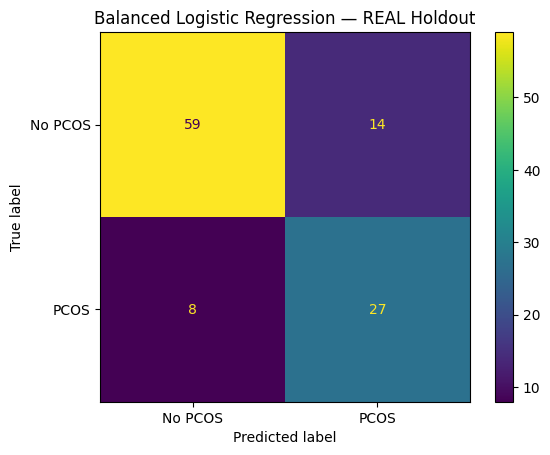

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_test_predictions,
    display_labels=[
        "No PCOS",
        "PCOS"
    ],
    values_format="d"
)

plt.title(
    f"{SELECTED_MODEL_NAME} — REAL Holdout"
)

plt.show()

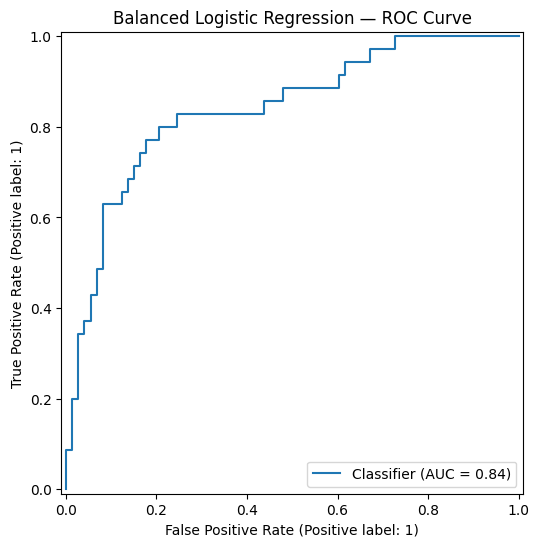

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))

RocCurveDisplay.from_predictions(
    y_test,
    final_test_probabilities,
    ax=ax
)

plt.title(
    f"{SELECTED_MODEL_NAME} — ROC Curve"
)

plt.show()

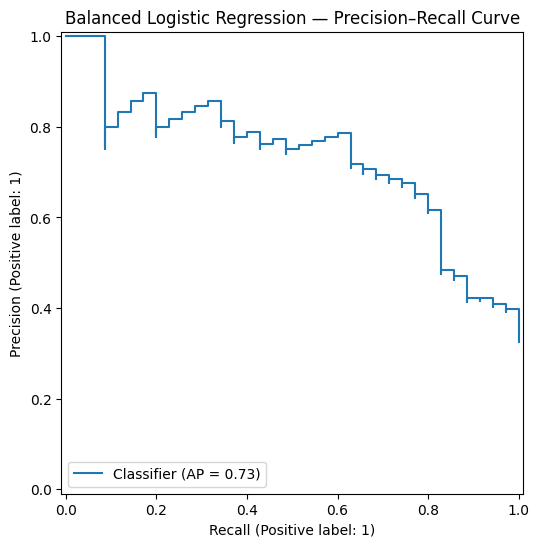

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))

PrecisionRecallDisplay.from_predictions(
    y_test,
    final_test_probabilities,
    ax=ax
)

plt.title(
    f"{SELECTED_MODEL_NAME} — Precision–Recall Curve"
)

plt.show()

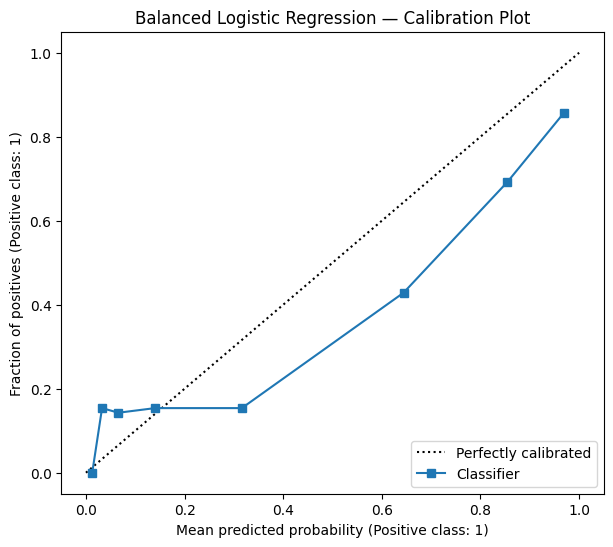

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))

CalibrationDisplay.from_predictions(
    y_test,
    final_test_probabilities,
    n_bins=8,
    strategy="quantile",
    ax=ax
)

plt.title(
    f"{SELECTED_MODEL_NAME} — Calibration Plot"
)

plt.show()

## Step 17 — Linear SHAP for the selected Logistic Regression model

For the expected final selection (**Balanced Logistic Regression**), the model is a preprocessing pipeline followed by Logistic Regression.

### Critical deployment rule

Prediction must use the **full fitted pipeline**, not the extracted Logistic Regression estimator on raw user values.

The Logistic Regression core receives transformed/scaled values in the preprocessor output order. Passing raw 14-feature values directly to that core estimator is incorrect.

For SHAP:

1. transform the REAL development background with the fitted preprocessor;
2. transform the observation to explain using the same preprocessor;
3. run `LinearExplainer` on the Logistic Regression core;
4. map SHAP values to the transformed feature names.

The SHAP background is based on the REAL development cohort rather than the synthetic observations.

In [ ]:
if "Logistic Regression" not in SELECTED_MODEL_NAME:
    raise ValueError(
        "The selected final model is not Logistic Regression. "
        "Do not use this Linear SHAP block without changing "
        "the explainer for the selected model type."
    )

final_preprocessor = (
    final_model
    .named_steps["preprocess"]
)

final_lr_core = (
    final_model
    .named_steps["model"]
)

SHAP_FEATURE_NAMES = (
    final_preprocessor
    .get_feature_names_out()
    .tolist()
)

X_shap_background_array = (
    final_preprocessor
    .transform(
        X_dev[FEATURE_COLUMNS]
    )
)

X_test_transformed_array = (
    final_preprocessor
    .transform(
        X_test[FEATURE_COLUMNS]
    )
)

X_shap_background = pd.DataFrame(
    X_shap_background_array,
    columns=SHAP_FEATURE_NAMES,
    index=X_dev.index
)

X_test_transformed = pd.DataFrame(
    X_test_transformed_array,
    columns=SHAP_FEATURE_NAMES,
    index=X_test.index
)

shap_masker = shap.maskers.Independent(
    X_shap_background,
    max_samples=len(
        X_shap_background
    )
)

linear_shap_explainer = shap.LinearExplainer(
    final_lr_core,
    shap_masker
)

final_shap_values = (
    linear_shap_explainer(
        X_test_transformed
    )
)

print(
    "✅ Linear SHAP generated for the selected "
    "Logistic Regression model"
)

print(
    "SHAP background samples:",
    len(X_shap_background)
)

print(
    "Explained REAL holdout samples:",
    len(X_test_transformed)
)

print(
    "SHAP feature order:"
)

print(
    SHAP_FEATURE_NAMES
)

✅ Linear SHAP generated for the selected Logistic Regression model
SHAP background samples: 432
Explained REAL holdout samples: 108
SHAP feature order:
['Age (yrs)', 'BMI', 'Cycle length(days)', 'Waist:Hip Ratio', 'Waist(inch)', 'Hip(inch)', 'Cycle(R/I)', 'Weight gain(Y/N)', 'hair growth(Y/N)', 'Skin darkening (Y/N)', 'Hair loss(Y/N)', 'Pimples(Y/N)', 'Fast food (Y/N)', 'Reg.Exercise(Y/N)']


## Step 18 — Global SHAP importance

Mean absolute SHAP values summarize model attribution magnitude over the REAL holdout.

They do **not** establish medical causality.

In [ ]:
global_shap_importance_df = pd.DataFrame({
    "Feature":
        SHAP_FEATURE_NAMES,

    "Mean Absolute SHAP":
        np.abs(
            final_shap_values.values
        ).mean(axis=0)
})

global_shap_importance_df = (
    global_shap_importance_df
    .sort_values(
        "Mean Absolute SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    global_shap_importance_df.round(6)
)

,Feature,Mean Absolute SHAP
0,Skin darkening (Y/N),0.702298
1,hair growth(Y/N),0.682619
2,Weight gain(Y/N),0.590265
3,Hair loss(Y/N),0.568533
4,Pimples(Y/N),0.505100
5,Cycle(R/I),0.485603
6,Fast food (Y/N),0.279658
7,Waist(inch),0.243112
8,Cycle length(days),0.240127
9,Age (yrs),0.187790


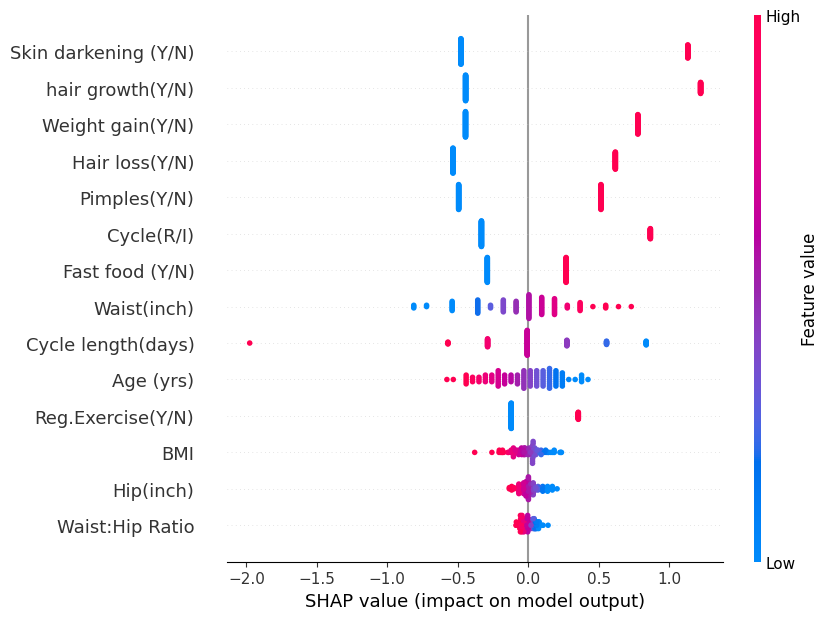

In [ ]:
shap.plots.beeswarm(
    final_shap_values,
    max_display=14
)

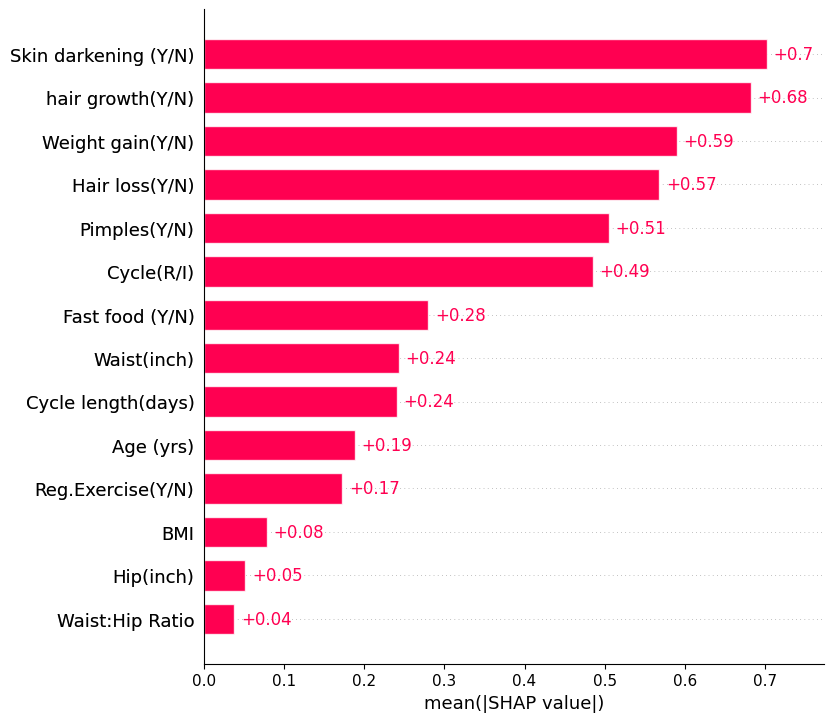

In [ ]:
shap.plots.bar(
    final_shap_values,
    max_display=14
)

## Step 19 — Local user prediction + SHAP explanation

This helper accepts **raw 14-feature user input**.

- Probability is produced by the **full fitted pipeline**.
- SHAP is calculated only after applying the fitted preprocessor.
- Positive SHAP values push the model output toward the positive PCOS class.
- Negative SHAP values push it away from the positive class.

This is model explanation, not causal or diagnostic interpretation.

In [ ]:
def predict_and_explain_user(
    raw_input,
    final_pipeline=final_model,
    explainer=linear_shap_explainer,
    threshold=SELECTED_THRESHOLD
):
    if isinstance(raw_input, dict):
        raw_df = pd.DataFrame(
            [raw_input]
        )
    else:
        raw_df = raw_input.copy()

    missing = [
        col for col in FEATURE_COLUMNS
        if col not in raw_df.columns
    ]

    if missing:
        raise ValueError(
            f"Missing user-input features: {missing}"
        )

    raw_df = raw_df[
        FEATURE_COLUMNS
    ].copy()

    probability = float(
        final_pipeline
        .predict_proba(
            raw_df
        )[0, 1]
    )

    prediction = int(
        probability
        >=
        threshold
    )

    preprocessor = (
        final_pipeline
        .named_steps["preprocess"]
    )

    transformed = (
        preprocessor
        .transform(
            raw_df
        )
    )

    transformed_df = pd.DataFrame(
        transformed,
        columns=SHAP_FEATURE_NAMES
    )

    explanation = explainer(
        transformed_df
    )

    shap_array = (
        explanation
        .values[0]
    )

    shap_table = pd.DataFrame({
        "Feature":
            SHAP_FEATURE_NAMES,

        "SHAP Value":
            shap_array,

        "Absolute SHAP":
            np.abs(shap_array)
    })

    shap_table["Direction"] = np.where(
        shap_table["SHAP Value"] >= 0,
        "toward PCOS class",
        "away from PCOS class"
    )

    shap_table = (
        shap_table
        .sort_values(
            "Absolute SHAP",
            ascending=False
        )
        .reset_index(drop=True)
    )

    shap_dict = {
        feature: float(value)

        for feature, value
        in zip(
            SHAP_FEATURE_NAMES,
            shap_array
        )
    }

    return {
        "prediction":
            prediction,

        "model_estimated_probability":
            probability,

        "classification_threshold":
            threshold,

        "shap_values":
            shap_dict,

        "shap_table":
            shap_table
    }


example_input = (
    X_test
    .iloc[[0]]
    .copy()
)

example_result = (
    predict_and_explain_user(
        example_input
    )
)

print(
    "Prediction:",
    example_result["prediction"]
)

print(
    "Model-estimated probability:",
    round(
        example_result[
            "model_estimated_probability"
        ],
        4
    )
)

display(
    example_result["shap_table"]
)

Prediction: 0
Model-estimated probability: 0.02


,Feature,SHAP Value,Absolute SHAP,Direction
0,Hair loss(Y/N),-0.533741,0.533741,away from PCOS class
1,Pimples(Y/N),-0.493408,0.493408,away from PCOS class
2,Skin darkening (Y/N),-0.477408,0.477408,away from PCOS class
3,Weight gain(Y/N),-0.444784,0.444784,away from PCOS class
4,hair growth(Y/N),-0.444207,0.444207,away from PCOS class
5,Cycle(R/I),-0.331790,0.331790,away from PCOS class
6,Fast food (Y/N),-0.290016,0.290016,away from PCOS class
7,Waist(inch),0.187195,0.187195,toward PCOS class
8,Reg.Exercise(Y/N),-0.120141,0.120141,away from PCOS class
9,Age (yrs),0.106161,0.106161,toward PCOS class


## Step 20 — Save the final deployment artifacts

### Files saved

- `pcos_balanced_logistic_pipeline.pkl` — **full prediction pipeline**; use this for raw user input.
- `pcos_logistic_preprocessor.pkl` — fitted preprocessing transformation.
- `pcos_balanced_logistic_core.pkl` — fitted Logistic Regression core; use with transformed inputs only.
- `pcos_feature_columns.pkl` — raw 14-feature input order.
- `pcos_shap_feature_names.pkl` — transformed feature order used by Linear SHAP.
- `pcos_shap_background_transformed.pkl` — REAL development background after fitted preprocessing.
- `pcos_model_metadata.pkl` — model/training/evaluation metadata.

The corrected artifacts are saved to a **new folder** first so they do not overwrite an older deployed model before validation.

In [ ]:
MODEL_DIR = (
    "/content/drive/MyDrive/"
    "pcos_rag/models"
)

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

PIPELINE_PATH = os.path.join(
    MODEL_DIR,
    "pcos_logistic_model.pkl"
)

PREPROCESSOR_PATH = os.path.join(
    MODEL_DIR,
    "pcos_logistic_preprocessor.pkl"
)

CORE_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "pcos_balanced_logistic_core.pkl"
)

FEATURE_COLUMNS_PATH = os.path.join(
    MODEL_DIR,
    "pcos_feature_columns.pkl"
)

SHAP_FEATURE_NAMES_PATH = os.path.join(
    MODEL_DIR,
    "pcos_shap_feature_names.pkl"
)

SHAP_BACKGROUND_PATH = os.path.join(
    MODEL_DIR,
    "pcos_shap_background.pkl"
)

METADATA_PATH = os.path.join(
    MODEL_DIR,
    "pcos_model_metadata.pkl"
)

joblib.dump(
    final_model,
    PIPELINE_PATH
)

joblib.dump(
    final_preprocessor,
    PREPROCESSOR_PATH
)

joblib.dump(
    final_lr_core,
    CORE_MODEL_PATH
)

joblib.dump(
    FEATURE_COLUMNS,
    FEATURE_COLUMNS_PATH
)

joblib.dump(
    SHAP_FEATURE_NAMES,
    SHAP_FEATURE_NAMES_PATH
)

joblib.dump(
    X_shap_background,
    SHAP_BACKGROUND_PATH
)

MODEL_METADATA = {
    "selected_model":
        SELECTED_MODEL_NAME,

    "training_configuration":
        SELECTED_TRAINING_CONFIGURATION,

    "classification_threshold":
        float(
            SELECTED_THRESHOLD
        ),

    "selection_primary_metric":
        "Balanced Accuracy",

    "selection_secondary_metrics":
        [
            "Recall",
            "F1",
            "MCC"
        ],

    "real_total_records":
        int(
            len(X_real)
        ),

    "real_development_records":
        int(
            len(X_dev)
        ),

    "real_holdout_records":
        int(
            len(X_test)
        ),

    "synthetic_available_records":
        int(
            len(X_synthetic)
        ),

    "final_training_records":
        int(
            len(X_final_train)
        ),

    "cv_scheme":
        "RepeatedStratifiedKFold(5 folds x 10 repeats)",

    "holdout_configuration":
        "REAL-only, evaluated after development selection",

    "shap_method":
        "Linear SHAP",

    "shap_background":
        "REAL development cohort after fitted preprocessing",

    "final_holdout_results":
        FINAL_HOLDOUT_RESULTS
}

joblib.dump(
    MODEL_METADATA,
    METADATA_PATH
)

print("✅ Corrected deployment artifacts saved")
print("\nFolder:")
print(MODEL_DIR)

print("\nPipeline:")
print(PIPELINE_PATH)

print("\nSHAP background:")
print(SHAP_BACKGROUND_PATH)

✅ Corrected deployment artifacts saved

Folder:
/content/drive/MyDrive/pcos_rag/models

Pipeline:
/content/drive/MyDrive/pcos_rag/models/pcos_logistic_model.pkl

SHAP background:
/content/drive/MyDrive/pcos_rag/models/pcos_shap_background.pkl


## Step 21 — Verify the saved prediction pipeline

The reloaded model should produce the same probability as the in-memory final model for the same raw input.

In [ ]:
reloaded_pipeline = joblib.load(
    PIPELINE_PATH
)

check_input = (
    X_test
    .iloc[[0]]
    .copy()
)

original_probability = float(
    final_model.predict_proba(
        check_input
    )[0, 1]
)

reloaded_probability = float(
    reloaded_pipeline.predict_proba(
        check_input
    )[0, 1]
)

print(
    "Original probability:",
    original_probability
)

print(
    "Reloaded probability:",
    reloaded_probability
)

assert np.isclose(
    original_probability,
    reloaded_probability
)

print(
    "\n✅ Saved full pipeline verified successfully"
)

Original probability: 0.019998836522282452
Reloaded probability: 0.019998836522282452

✅ Saved full pipeline verified successfully


In [30]:
import pandas as pd
from google.colab import files

# Combine synthetic features and target into a single DataFrame
synthetic_df = X_synthetic.copy()
synthetic_df[TARGET] = y_synthetic

# Save to Excel file
output_filename = "PCOS_600_rule_based_dataset.xlsx"
synthetic_df.to_excel(output_filename, index=False)
print(f"✅ Saved dataset locally as: {output_filename}")

# Trigger browser download
files.download(output_filename)

✅ Saved dataset locally as: PCOS_600_rule_based_dataset.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>